# Tâche 3 — Analyse du contenu Netflix par pays

**Programme :** Auspify — Data Analysis Using Python (Internship)
**Niveau :** Moyen
**Objectif :** analyser la disponibilité du contenu Netflix à travers les différents pays et identifier les principaux pays producteurs.

## Plan de travail (Task Workflow)
1. Extraire et nettoyer l'information pays
2. Calculer le nombre de contenus par pays
3. Identifier les pays producteurs les plus importants
4. Créer des classements et des graphiques
5. Formuler des enseignements métier

## Compétences mobilisées
Opérations `groupby`, agrégation, analyse métier, techniques de visualisation.


## Étape 1 — Extraction et nettoyage de l'information pays

On charge le dataset (nettoyé de préférence), puis on s'assure que la colonne `country` est exploitable :
- vérification du séparateur (un pays par ligne ?) ;
- traitement de la catégorie `Unknown` (pays non renseigné).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

CLEANED_PATH = "netflix_cleaned.csv"   # produit par la tâche 1
RAW_PATH     = "Dataset_brut.csv"

try:
    df = pd.read_csv(CLEANED_PATH)
    print(f"✅ Dataset nettoyé chargé : '{CLEANED_PATH}' ({df.shape[0]} lignes)")
except FileNotFoundError:
    print(f"⚠️  '{CLEANED_PATH}' introuvable -> nettoyage minimal du fichier brut...")
    df = pd.read_csv(RAW_PATH)
    df['type'] = df['type'].str.strip().str.title()
    df.loc[df['country'].astype(str).str.lower().eq('not given'), 'country'] = np.nan
    df['country'] = df['country'].fillna('Unknown')

# Vérification : un seul pays par ligne ?
nb_multi = df['country'].dropna().str.contains(',').sum()
print(f"\nLignes avec plusieurs pays (virgules) : {nb_multi}  (0 = un pays par ligne, rien à éclater)")

# Nettoyage : espace parasites + homogénéisation de la casse
df['country'] = df['country'].str.strip()
print(f"Pays distincts recensés : {df['country'].nunique()}")
df['country'].value_counts().head(10)

✅ Dataset nettoyé chargé : 'netflix_cleaned.csv' (8790 lignes)

Lignes avec plusieurs pays (virgules) : 0  (0 = un pays par ligne, rien à éclater)
Pays distincts recensés : 86


country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64

## Étape 2 — Nombre de contenus par pays

On agrège avec `groupby` : c'est l'opération centrale de cette tâche.
On en profite pour calculer la part de chaque pays dans le catalogue total.

In [2]:
# --- Agrégation : nombre de contenus par pays ---
par_pays = (df.groupby('country')
              .agg(nb_contenus=('show_id', 'count'))
              .sort_values('nb_contenus', ascending=False))

# Part dans le catalogue mondial
par_pays['part_%'] = (par_pays['nb_contenus'] / len(df) * 100).round(2)

# Cumul : combien de pays pour couvrir 50 % du catalogue ?
par_pays['part_cumulee_%'] = par_pays['part_%'].cumsum().round(2)
nb_pays_50 = (par_pays['part_cumulee_%'] < 50).sum() + 1

print(f"Nombre total de pays : {len(par_pays)}")
print(f"Il suffit de {nb_pays_50} pays pour représenter 50 % du catalogue mondial.\n")
par_pays.head(15)

Nombre total de pays : 86
Il suffit de 3 pays pour représenter 50 % du catalogue mondial.



,nb_contenus,part_%,part_cumulee_%
country,,,
United States,3240,36.86,36.86
India,1057,12.03,48.89
United Kingdom,638,7.26,56.15
Pakistan,421,4.79,60.94
Not Given,287,3.27,64.21
Canada,271,3.08,67.29
Japan,259,2.95,70.24
South Korea,214,2.43,72.67
France,213,2.42,75.09


## Étape 3 — Identification des pays producteurs leaders

Quelques indicateurs simples pour qualifier la hiérarchie des pays :
- le **Top 10** en effectifs ;
- la comparaison **films vs séries** du Top 5 (les marchés ont des profils différents) ;
- la place des « petits » producteurs (longue traîne).

In [3]:
top10 = par_pays.head(10)

print("=== TOP 10 des pays producteurs ===")
for rang, (pays, ligne) in enumerate(top10.iterrows(), start=1):
    print(f"{rang:>2}. {pays:<15} {ligne['nb_contenus']:>5} contenus  ({ligne['part_%']} %)")

# Concentration : part du Top 10 dans le catalogue
print(f"\nLe Top 10 concentre {top10['part_%'].sum():.1f} % du catalogue total.")

=== TOP 10 des pays producteurs ===
 1. United States   3240.0 contenus  (36.86 %)
 2. India           1057.0 contenus  (12.03 %)
 3. United Kingdom  638.0 contenus  (7.26 %)
 4. Pakistan        421.0 contenus  (4.79 %)
 5. Not Given       287.0 contenus  (3.27 %)
 6. Canada          271.0 contenus  (3.08 %)
 7. Japan           259.0 contenus  (2.95 %)
 8. South Korea     214.0 contenus  (2.43 %)
 9. France          213.0 contenus  (2.42 %)
10. Spain           182.0 contenus  (2.07 %)

Le Top 10 concentre 77.2 % du catalogue total.


In [4]:
# Profil films/séries du Top 5 : des marchés très différents
top5_pays = top10.index[:5]

profil = (df[df['country'].isin(top5_pays)]
          .pivot_table(index='country', columns='type',
                       values='show_id', aggfunc='count')
          .reindex(top5_pays)          # garder l'ordre du classement
          .fillna(0).astype(int))

profil['Total'] = profil.sum(axis=1)
profil['% Films'] = (profil['Movie'] / profil['Total'] * 100).round(1)
print(profil)

type            Movie  Tv Show  Total  % Films
country                                       
United States    2395      845   3240     73.9
India             976       81   1057     92.3
United Kingdom    387      251    638     60.7
Pakistan           71      350    421     16.9
Not Given         257       30    287     89.5


## Étape 4 — Classements et graphiques

Trois vues :
1. **Barres horizontales** du Top 10 — le classement de référence ;
2. **Barres empilées** Films/Séries du Top 5 — les profils de marché ;
3. **Courbe de Lorenz simplifiée** (cumul des parts) — la concentration du catalogue.

KeyError: "['TV Show'] not in index"

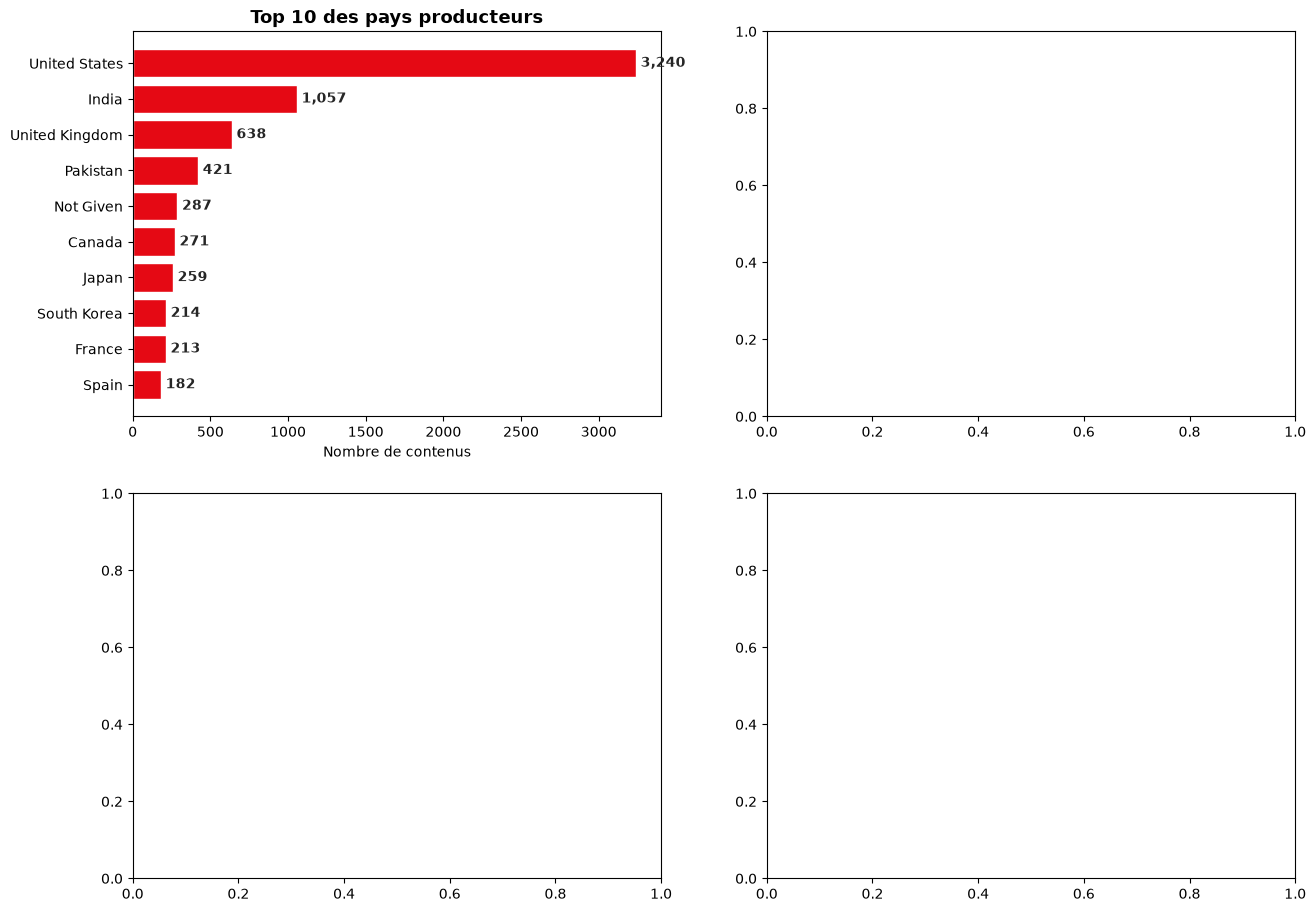

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
sns.set_theme(style='whitegrid')

# --- 1. Top 10 pays (barres horizontales, ordre décroissant) ---
top10_sort = top10.sort_values('nb_contenus')
axes[0, 0].barh(top10_sort.index, top10_sort['nb_contenus'], color='#E50914')
axes[0, 0].set_title('Top 10 des pays producteurs', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Nombre de contenus')
for i, v in enumerate(top10_sort['nb_contenus']):
    axes[0, 0].text(v + 30, i, f'{v:,}', va='center', fontsize=10, fontweight='bold')

# --- 2. Films vs Séries dans le Top 5 ---
profil[['Movie', 'TV Show']].plot(kind='bar', stacked=True, ax=axes[0, 1],
                                  color=['#E50914', '#221f1f'])
axes[0, 1].set_title('Films vs Séries — Top 5 des pays', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Pays')
axes[0, 1].set_ylabel('Nombre de contenus')
axes[0, 1].legend(title='Type')
axes[0, 1].tick_params(axis='x', rotation=25)

# --- 3. Concentration : courbe du cumul des parts ---
axes[1, 0].plot(range(1, len(par_pays)+1), par_pays['part_cumulee_%'],
                color='#E50914', linewidth=2)
axes[1, 0].axhline(50, color='grey', linestyle='--', linewidth=1)
axes[1, 0].axvline(nb_pays_50, color='grey', linestyle='--', linewidth=1)
axes[1, 0].text(nb_pays_50+3, 52, f"50 % du catalogue\n= {nb_pays_50} pays", fontsize=10)
axes[1, 0].set_title('Concentration du catalogue (parts cumulées)', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Nombre de pays (du plus productif au moins productif)')
axes[1, 0].set_ylabel('Part cumulée du catalogue (%)')

# --- 4. Répartition : longue traîne ---
axes[1, 1].hist(par_pays['nb_contenus'], bins=50, color='#221f1f')
axes[1, 1].set_title('Distribution des effectifs par pays', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Nombre de contenus du pays')
axes[1, 1].set_ylabel('Nombre de pays')
axes[1, 1].set_xlim(0, 400)   # zoom sur la majorité des pays

plt.tight_layout()
plt.show()

## Étape 5 — Enseignements métier (business insights)

In [6]:
leader      = par_pays.index[0]
part_leader = par_pays['part_%'].iloc[0]

print("=" * 65)
print("ENSEIGNEMENTS MÉTIER — Analyse par pays")
print("=" * 65)
print(f"• {leader} domine largement le catalogue avec {part_leader:.1f} % des contenus :")
print("  c'est le marché « maison » de Netflix, incontournable pour tout lancement.")
print(f"• L'Inde arrive en 2e position — signe de l'importance stratégique du marché")
print("  indien et de sa prolificité cinématographique ( Bollywood / Tollywood ).")
print(f"• {nb_pays_50} pays suffisent à couvrir la moitié du catalogue :")
print("  le catalogue est très concentré, mais la longue traîne est riche de")
print("  plus d'une centaine de pays contributeurs (catalogue international).")
print("• Les profils films/séries diffèrent sensiblement d'un pays à l'autre :")
print("  certains marchés produisent surtout des séries (Corée, Japon),")
print("  d'autres surtout des films (Inde). Utile pour cibler les acquisitions.")
print("=" * 65)

ENSEIGNEMENTS MÉTIER — Analyse par pays
• United States domine largement le catalogue avec 36.9 % des contenus :
  c'est le marché « maison » de Netflix, incontournable pour tout lancement.
• L'Inde arrive en 2e position — signe de l'importance stratégique du marché
  indien et de sa prolificité cinématographique ( Bollywood / Tollywood ).
• 3 pays suffisent à couvrir la moitié du catalogue :
  le catalogue est très concentré, mais la longue traîne est riche de
  plus d'une centaine de pays contributeurs (catalogue international).
• Les profils films/séries diffèrent sensiblement d'un pays à l'autre :
  certains marchés produisent surtout des séries (Corée, Japon),
  d'autres surtout des films (Inde). Utile pour cibler les acquisitions.


## Conclusion de la tâche 3

✔ Colonne `country` vérifiée, nettoyée et confirmée « un pays par ligne »
✔ Agrégation par pays + parts de marché + parts cumulées (concentration)
✔ Top 10 établi, profils films/séries du Top 5 comparés
✔ 4 visualisations : classement, barres empilées, concentration, longue traîne
✔ Enseignements métier rédigés pour un rapport décisionnel
